## Import dan Konfigurasi

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision import transforms, models

# Konfigurasi perangkat dan label
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASSES = ['Rp100', 'Rp1000', 'Rp200', 'Rp500']
NOTEBOOK_DIR = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\notebook')
DIAGRAM_DIR  = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\diagram')
DATASET_DIR  = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\dataset_koin_baru')

# Preprocessing evaluasi (anti-gepeng)
infer_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

print(f'Device: {DEVICE}')
print(f'Kelas : {CLASSES}')

Device: cpu
Kelas : ['Rp100', 'Rp1000', 'Rp200', 'Rp500']


## Muat Model GoogLeNet

In [2]:
# Inisialisasi arsitektur GoogLeNet
model_googlenet = models.googlenet(weights=None)
model_googlenet.aux_logits = False
model_googlenet.aux1 = None
model_googlenet.aux2 = None
model_googlenet.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(model_googlenet.fc.in_features, len(CLASSES))
)

# Muat bobot checkpoint terbaik GoogLeNet
ckpt_gnet = DIAGRAM_DIR / 'best_googlenet.pt'
model_googlenet.load_state_dict(torch.load(ckpt_gnet, map_location=DEVICE))
model_googlenet.to(DEVICE)
model_googlenet.eval()
print(f'GoogLeNet berhasil dimuat dari: {ckpt_gnet.name}')

C:\Users\Bunga Alyssa\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\googlenet.py:47: FutureWarning: The default weight initialization of GoogleNet will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


GoogLeNet berhasil dimuat dari: best_googlenet.pt


## Muat Model MobileNetV2

In [3]:
# Inisialisasi arsitektur MobileNetV2
model_mobilenet = models.mobilenet_v2(weights=None)
in_features = model_mobilenet.classifier[1].in_features
model_mobilenet.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(in_features, len(CLASSES))
)

# Muat bobot checkpoint terbaik MobileNetV2
ckpt_mbnet = DIAGRAM_DIR / 'best_mobilenetv2.pt'
model_mobilenet.load_state_dict(torch.load(ckpt_mbnet, map_location=DEVICE))
model_mobilenet.to(DEVICE)
model_mobilenet.eval()
print(f'MobileNetV2 berhasil dimuat dari: {ckpt_mbnet.name}')

MobileNetV2 berhasil dimuat dari: best_mobilenetv2.pt


## Definisi Fungsi Prediksi dan Visualisasi

In [4]:
def uji_koin(image_path, model, nama_model='GoogLeNet', label_asli=None):
    path = Path(image_path)
    img_pil = Image.open(path).convert('RGB')
    tensor = infer_tf(img_pil).unsqueeze(0).to(DEVICE)

    # Hitung waktu inferensi
    t0 = time.time()
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    durasi_ms = (time.time() - t0) * 1000

    pred_idx = int(np.argmax(probs))
    pred_label = CLASSES[pred_idx]
    pred_conf = probs[pred_idx] * 100

    # Visualisasi gambar dan probabilitas
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4))

    ax_img.imshow(img_pil)
    judul = f'Prediksi: {pred_label} ({pred_conf:.1f}%)'
    if label_asli:
        judul += f'\nAktual: {label_asli}'
    warna = 'green' if (label_asli is None or pred_label == label_asli) else 'red'
    ax_img.set_title(judul, fontsize=11, color=warna, fontweight='bold')
    ax_img.axis('off')

    # Diagram batang probabilitas horizontal
    urutan = np.argsort(probs)
    warna_bar = ['#2ca02c' if i == pred_idx else '#1f77b4' for i in urutan]
    ax_bar.barh([CLASSES[i] for i in urutan], [probs[i] * 100 for i in urutan], color=warna_bar)
    ax_bar.set_xlim(0, 105)
    ax_bar.set_xlabel('Probabilitas (%)')
    ax_bar.set_title(f'Tingkat Keyakinan ({nama_model})', fontsize=11)
    for i, idx in enumerate(urutan):
        ax_bar.text(probs[idx] * 100 + 1, i, f'{probs[idx]*100:.1f}%', va='center', fontsize=9)
    ax_bar.grid(axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    print(f'File         : {path.name}')
    print(f'Prediksi     : {pred_label} (Keyakinan: {pred_conf:.2f}%)')
    if label_asli:
        print(f'Label Aktual : {label_asli} -> Status: {"BENAR" if pred_label == label_asli else "SALAH"}')
    print(f'Waktu Infer  : {durasi_ms:.2f} ms')
    return pred_label, pred_conf

## Uji Koin Rp100 (Sisi Depan)

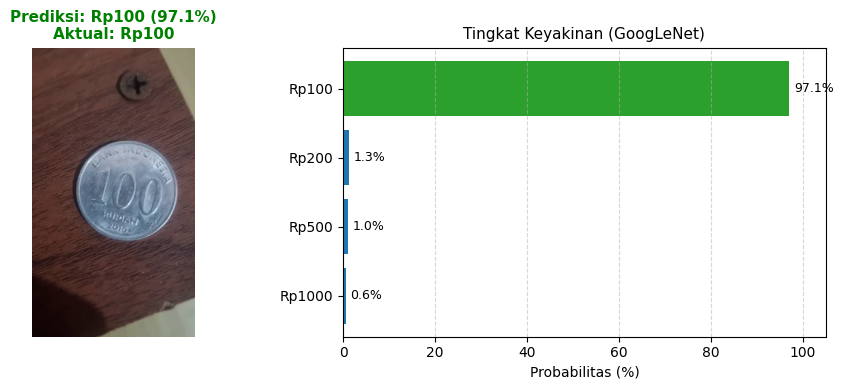

File         : WhatsApp_Video_2026_11_01_at_20_15_37_f00000.png
Prediksi     : Rp100 (Keyakinan: 97.10%)
Label Aktual : Rp100 -> Status: BENAR
Waktu Infer  : 99.52 ms


('Rp100', 97.10437655448914)

In [5]:
sample_100 = DATASET_DIR / '100' / 'WhatsApp_Video_2026_11_01_at_20_15_37_f00000.png'
uji_koin(sample_100, model_googlenet, nama_model='GoogLeNet', label_asli='Rp100')

## Uji Koin Rp200 (Sisi Belakang)

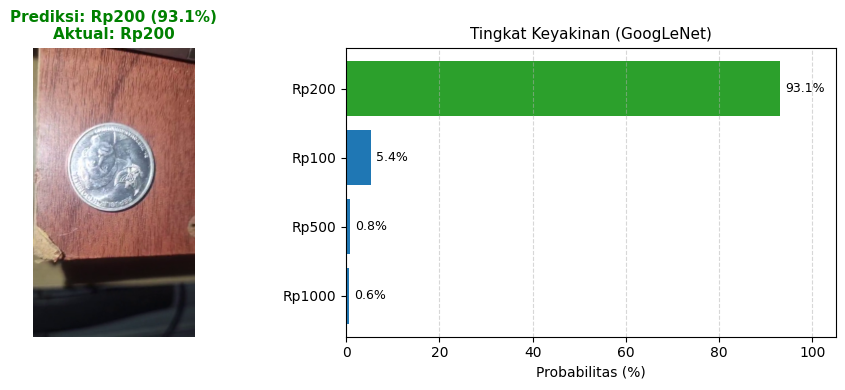

File         : WhatsApp_Video_2026_11_01_at_20_18_19_f00072.png
Prediksi     : Rp200 (Keyakinan: 93.14%)
Label Aktual : Rp200 -> Status: BENAR
Waktu Infer  : 56.53 ms


('Rp200', 93.13876628875732)

In [6]:
sample_200 = DATASET_DIR / 'balik_200' / 'WhatsApp_Video_2026_11_01_at_20_18_19_f00072.png'
uji_koin(sample_200, model_googlenet, nama_model='GoogLeNet', label_asli='Rp200')

## Uji Koin Rp500 (Foto Mandiri)

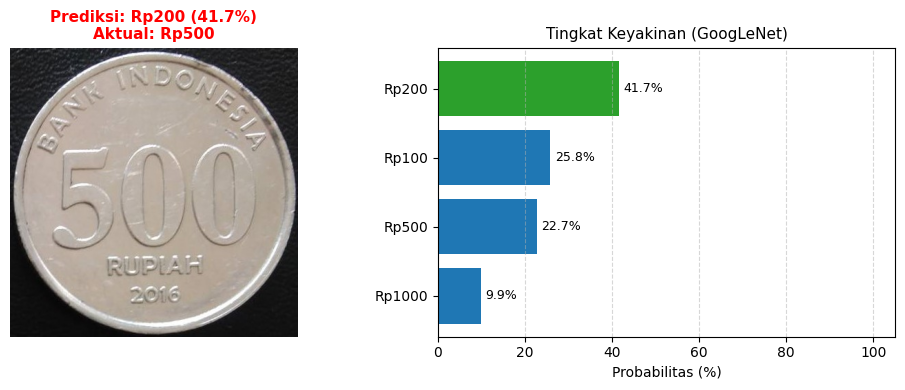

File         : image copy.png
Prediksi     : Rp200 (Keyakinan: 41.65%)
Label Aktual : Rp500 -> Status: SALAH
Waktu Infer  : 51.00 ms


('Rp200', 41.65355563163757)

In [7]:
sample_500 = DATASET_DIR / '500' / 'image copy.png'
uji_koin(sample_500, model_googlenet, nama_model='GoogLeNet', label_asli='Rp500')

## Uji Koin Rp1000 (Sisi Depan)

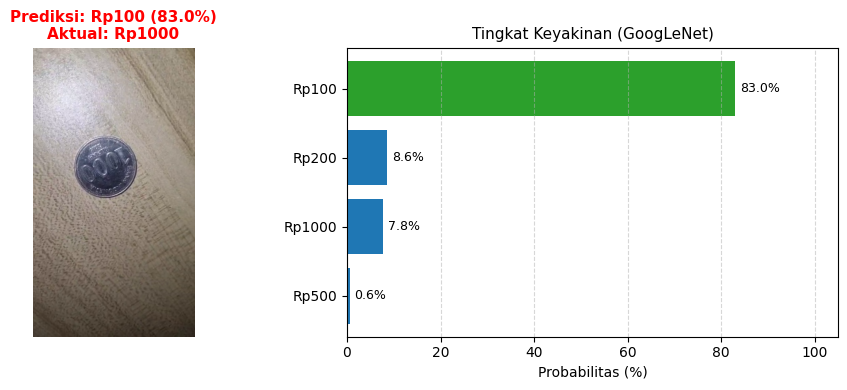

File         : WhatsApp_Video_2026_11_01_at_20_23_32_f00360.png
Prediksi     : Rp100 (Keyakinan: 82.99%)
Label Aktual : Rp1000 -> Status: SALAH
Waktu Infer  : 60.52 ms


('Rp100', 82.98684358596802)

In [8]:
sample_1000 = DATASET_DIR / '1000' / 'WhatsApp_Video_2026_11_01_at_20_23_32_f00360.png'
uji_koin(sample_1000, model_googlenet, nama_model='GoogLeNet', label_asli='Rp1000')

## Uji Foto Koin Resolusi Tinggi Asli Kamera

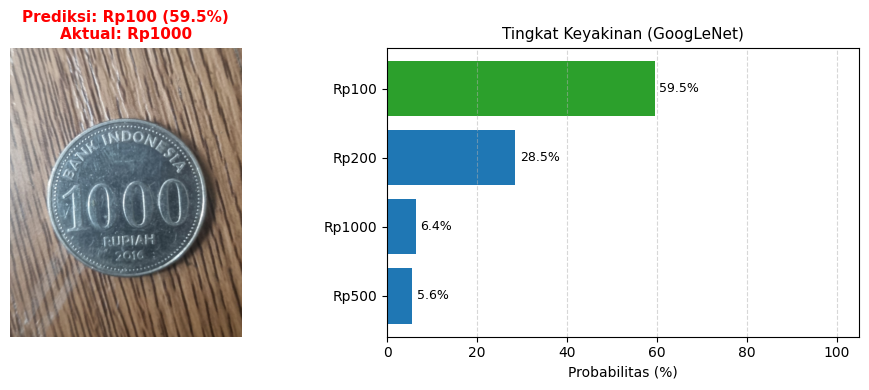

File         : 20251117_101945.jpg
Prediksi     : Rp100 (Keyakinan: 59.52%)
Label Aktual : Rp1000 -> Status: SALAH
Waktu Infer  : 84.26 ms


('Rp100', 59.52037572860718)

In [9]:
# Uji foto resolusi tinggi kamera HP asli (1736 x 2170 pixel)
foto_kamera = DATASET_DIR / '1000' / '20251117_101945.jpg'
uji_koin(foto_kamera, model_googlenet, nama_model='GoogLeNet', label_asli='Rp1000')

## Perbandingan Prediksi GoogLeNet vs MobileNetV2

=== HASIL PREDIKSI GOOGLENET ===


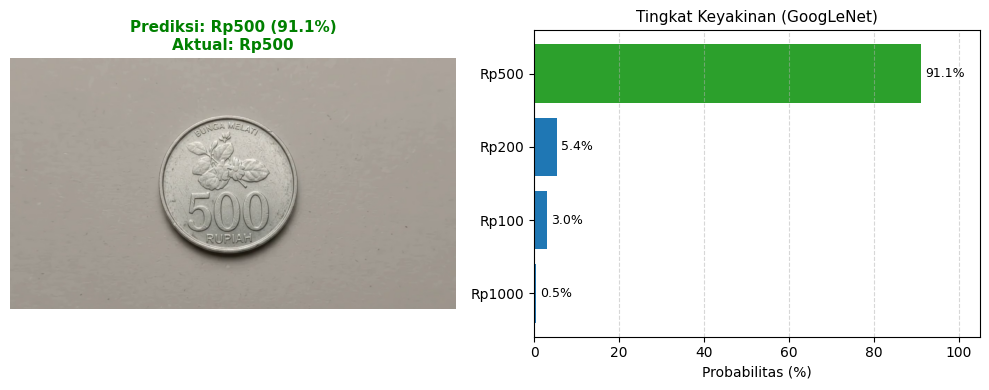

File         : gemini_generated_video_ff2c6568_f00010.png
Prediksi     : Rp500 (Keyakinan: 91.11%)
Label Aktual : Rp500 -> Status: BENAR
Waktu Infer  : 45.96 ms

=== HASIL PREDIKSI MOBILENETV2 ===


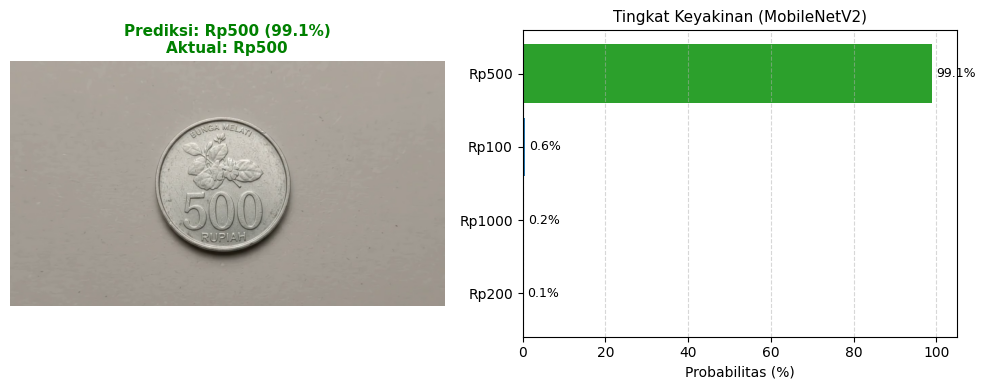

File         : gemini_generated_video_ff2c6568_f00010.png
Prediksi     : Rp500 (Keyakinan: 99.05%)
Label Aktual : Rp500 -> Status: BENAR
Waktu Infer  : 42.00 ms


('Rp500', 99.05117154121399)

In [10]:
# Uji satu sampel yang sama pada kedua model
sample_test = DATASET_DIR / '500' / 'gemini_generated_video_ff2c6568_f00010.png'
print('=== HASIL PREDIKSI GOOGLENET ===')
uji_koin(sample_test, model_googlenet, nama_model='GoogLeNet', label_asli='Rp500')
print('\n=== HASIL PREDIKSI MOBILENETV2 ===')
uji_koin(sample_test, model_mobilenet, nama_model='MobileNetV2', label_asli='Rp500')

## Uji Koin Acak dari Test Set

--------------------------------------------------


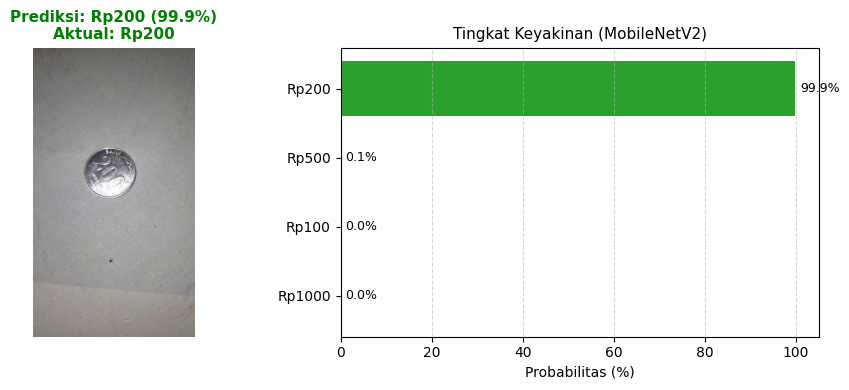

File         : WhatsApp_Video_2026_11_01_at_20_20_44_f00324.png
Prediksi     : Rp200 (Keyakinan: 99.89%)
Label Aktual : Rp200 -> Status: BENAR
Waktu Infer  : 31.52 ms
--------------------------------------------------


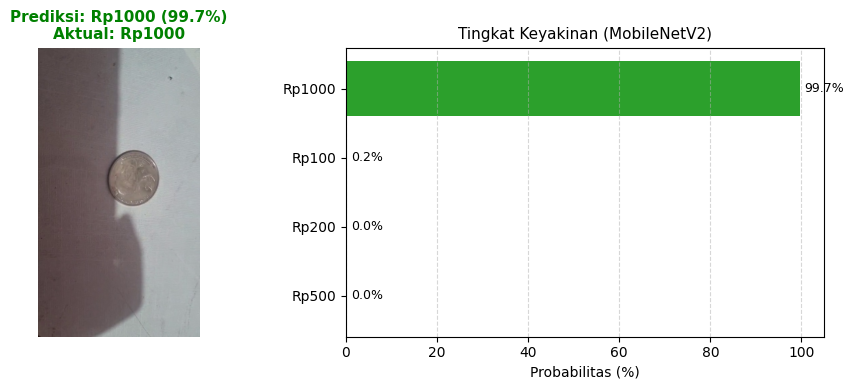

File         : WhatsApp_Video_2026_11_01_at_20_25_40_f00187.png
Prediksi     : Rp1000 (Keyakinan: 99.72%)
Label Aktual : Rp1000 -> Status: BENAR
Waktu Infer  : 25.08 ms
--------------------------------------------------


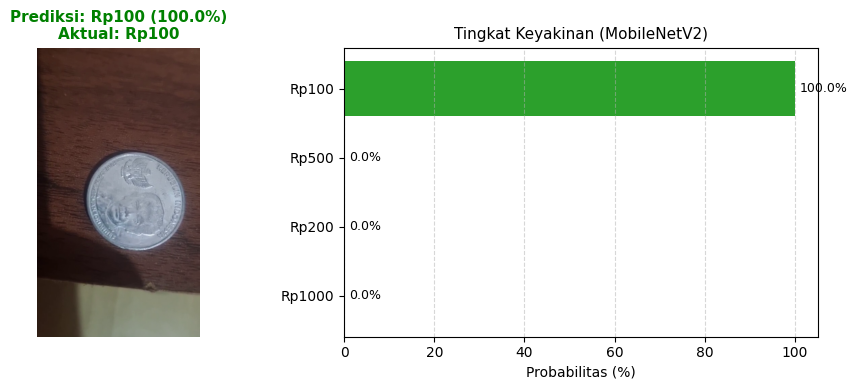

File         : WhatsApp_Video_2026_11_01_at_20_15_47_f00240.png
Prediksi     : Rp100 (Keyakinan: 99.95%)
Label Aktual : Rp100 -> Status: BENAR
Waktu Infer  : 25.00 ms


In [11]:
df_split = pd.read_csv(NOTEBOOK_DIR / 'split.csv')
df_test = df_split[df_split['subset'] == 'test']

# Ambil 3 sampel uji acak
acak_samples = df_test.sample(3, random_state=42)
for _, row in acak_samples.iterrows():
    print('-' * 50)
    uji_koin(row['path'], model_mobilenet, nama_model='MobileNetV2', label_asli=row['label'])